MARKETING CAMPAIGN ANALYSIS
============================

PROBLEM DEFINITION:
==================

To Analyze Customer acquisition With Exploratory data analysis and Hypothesis testing using Marketing Mix Strategy

Data description:
================

The dataset aligns with the Four Ps of Marketing, Product, Price, Place and Promotion. This structured approach helps businesses optimize products, pricing, distribution, and promotions for better customer engagement and market performance.


STEP1 : Import Data and examine Variables (DATA COLLECTION)

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats.mstats import winsorize
pd.options.display.float_format = '{:.2f}'.format 
from statsmodels.stats.weightstats import ztest

sns.set_theme(style='whitegrid')

# Read the marketing data CSV file into a pandas DataFrame

df = pd.read_csv('marketing_data.csv') # read the dataset into a pandas DataFrame
print("Dataset shape (rows,columns) : ",df.shape) # print the shape of the dataset
print("\nPreview Dataset : ")
df.head(10)  # View the first 10 rows of the dataset

Dataset shape (rows,columns) :  (2240, 28)

Preview Dataset : 


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP
5,7348,1958,PhD,Single,"$71,691.00",0,0,3/17/14,0,336,...,5,2,0,0,0,0,0,1,0,SP
6,4073,1954,2n Cycle,Married,"$63,564.00",0,0,1/29/14,0,769,...,7,6,1,0,0,0,0,1,0,GER
7,1991,1967,Graduation,Together,"$44,931.00",0,1,1/18/14,0,78,...,3,5,0,0,0,0,0,0,0,SP
8,4047,1954,PhD,Married,"$65,324.00",0,1,1/11/14,0,384,...,9,4,0,0,0,0,0,0,0,US
9,9477,1954,PhD,Married,"$65,324.00",0,1,1/11/14,0,384,...,9,4,0,0,0,0,0,0,0,IND


In [2]:
print("\nDataset Information : \n=====================\n")
print(df.info())  #check for the data types and null values in the dataset



Dataset Information : 

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   2240 non-null   int64
 1   Year_Birth           2240 non-null   int64
 2   Education            2240 non-null   str  
 3   Marital_Status       2240 non-null   str  
 4    Income              2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   Dt_Customer          2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProds         2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurc

In [3]:
# Check for column name length, as the Income column name looks spaced out

print("\nColumn Names and their Lengths : \n================================\n")
for c in df.columns:
    print(repr(c), len(c))



Column Names and their Lengths : 

'ID' 2
'Year_Birth' 10
'Education' 9
'Marital_Status' 14
' Income ' 8
'Kidhome' 7
'Teenhome' 8
'Dt_Customer' 11
'Recency' 7
'MntWines' 8
'MntFruits' 9
'MntMeatProducts' 15
'MntFishProducts' 15
'MntSweetProducts' 16
'MntGoldProds' 12
'NumDealsPurchases' 17
'NumWebPurchases' 15
'NumCatalogPurchases' 19
'NumStorePurchases' 17
'NumWebVisitsMonth' 17
'AcceptedCmp3' 12
'AcceptedCmp4' 12
'AcceptedCmp5' 12
'AcceptedCmp1' 12
'AcceptedCmp2' 12
'Response' 8
'Complain' 8
'Country' 7


In [4]:
Column_version1 = pd.DataFrame({'column': list(df.columns),
                    'name_version1': [repr(c) for c in df.columns],
                    'length_version1': [len(c) for c in df.columns]})

OBSERVATION : 

1. Non null count is less than expected for "Income" column. Information shows "2216" count, all other columns have "2240" count
2. "Income" column name have whitespace and have number values, so it is expected to be Integer format but is categorized as STRING format
3. Date of customer's enrollment with the company, "Dt_customer" is categorized as STRING format but from the preview it shows date format


STEP2: DATA CLEANING 

the listed issues in step1 need to be resolved

In [5]:
# copy raw data for future reference, as we will be cleaning up the column names and removing outliers from the dataset

df_raw = df.copy()                                     # untouched copy

# Remove extra spaces from all column names, cleanup names then display which names were modified

df.columns = df.columns.str.strip()        # remove extra spaces from all column names

Column_mod_version2 = pd.DataFrame({'column': list(df.columns),
                    'name_version2': [repr(c) for c in df.columns],
                    'length_version2': [len(c) for c in df.columns]})


# compare and see which columns changed after modification

print("\nIncome column name & length from dataset after modification\n\n")  


compare = pd.DataFrame({'Column name': Column_version1['name_version1'],
                        'Length': Column_version1['length_version1'],
                        'Column name -V2': Column_mod_version2['name_version2'],
                        'Length-V2': Column_mod_version2['length_version2']})
Result = []
for i in range(len(compare)):
    if compare['Length'][i] == compare['Length-V2'][i]:
        Result.append('not modified')
    else:
        Result.append('modified')
compare['Result'] = Result
modified_rows = compare[compare['Result'] == 'modified']
modified_rows

# compare (use if all columns comparison are needed)
# df column names are cleaned up



Income column name & length from dataset after modification




,Column name,Length,Column name -V2,Length-V2,Result
4,' Income ',8,'Income',6,modified


In [6]:
# Income column format conversion from string to float, Data Transformation

df['Income'] = (df['Income'].str.replace('$', '', regex=False)) # remove the $ sign from the Income column
df['Income'] = df['Income'].str.replace(',', '', regex=False)   # remove the , from the Income column
df['Income'] = pd.to_numeric(df['Income'], errors='coerce')     # convert the Income column to numeric
df['Income'].info() 
print("\n Preview dataset \n ")
df.head(10)

<class 'pandas.Series'>
RangeIndex: 2240 entries, 0 to 2239
Series name: Income
Non-Null Count  Dtype  
--------------  -----  
2216 non-null   float64
dtypes: float64(1)
memory usage: 17.6 KB

 Preview dataset 
 


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.00,0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,57091.00,0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,67267.00,0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,32474.00,1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,21474.00,1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP
5,7348,1958,PhD,Single,71691.00,0,0,3/17/14,0,336,...,5,2,0,0,0,0,0,1,0,SP
6,4073,1954,2n Cycle,Married,63564.00,0,0,1/29/14,0,769,...,7,6,1,0,0,0,0,1,0,GER
7,1991,1967,Graduation,Together,44931.00,0,1,1/18/14,0,78,...,3,5,0,0,0,0,0,0,0,SP
8,4047,1954,PhD,Married,65324.00,0,1,1/11/14,0,384,...,9,4,0,0,0,0,0,0,0,US
9,9477,1954,PhD,Married,65324.00,0,1,1/11/14,0,384,...,9,4,0,0,0,0,0,0,0,IND


In [7]:
# Dt_Customer column format conversion from string to datetime, Data Transformation

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%m/%d/%y')
df['Dt_Customer'].info() 
print("\n Preview dataset \n ")
df.head(10)

<class 'pandas.Series'>
RangeIndex: 2240 entries, 0 to 2239
Series name: Dt_Customer
Non-Null Count  Dtype         
--------------  -----         
2240 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 17.6 KB

 Preview dataset 
 


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,84835.00,0,0,2014-06-16,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,57091.00,0,0,2014-06-15,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,67267.00,0,1,2014-05-13,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,32474.00,1,1,2014-05-11,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,21474.00,1,0,2014-04-08,0,6,...,2,7,1,0,0,0,0,1,0,SP
5,7348,1958,PhD,Single,71691.00,0,0,2014-03-17,0,336,...,5,2,0,0,0,0,0,1,0,SP
6,4073,1954,2n Cycle,Married,63564.00,0,0,2014-01-29,0,769,...,7,6,1,0,0,0,0,1,0,GER
7,1991,1967,Graduation,Together,44931.00,0,1,2014-01-18,0,78,...,3,5,0,0,0,0,0,0,0,SP
8,4047,1954,PhD,Married,65324.00,0,1,2014-01-11,0,384,...,9,4,0,0,0,0,0,0,0,US
9,9477,1954,PhD,Married,65324.00,0,1,2014-01-11,0,384,...,9,4,0,0,0,0,0,0,0,IND


missing Income values in Income column: 24

 Education-wise Income Analysis:
     Education  Value_Count  Income_Count  Mean_Income  Missing_Count
0    2n Cycle          203           200     47633.19              3
1       Basic           54            54     20306.26              0
2  Graduation         1127          1116     52720.37             11
3      Master          370           365     52917.53              5
4         PhD          486           481     56145.31              5

 Marital Status-wise Income Analysis:
   Marital_Status  Value_Count  Income_Count  Mean_Income  Missing_Count
0         Absurd            2             2     72365.50              0
1          Alone            3             3     43789.00              0
2       Divorced          232           232     52834.23              0
3        Married          864           857     51724.98              7
4         Single          480           471     50995.35              9
5       Together          580       

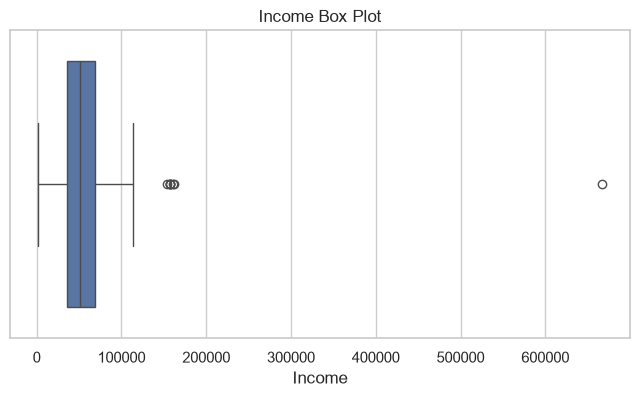

In [8]:
# Income column null values check

print("missing Income values in Income column:", df['Income'].isnull().sum())

# Education and Martial status tend to have comparable incomes, so null Income values can be imputed with the median of the respective Education and Martial status group.

# Cleansing the Education and Marital status columns

# Aggregating data - We need to have a brief understanding of the income distribution across education and marital status groups


Mean_comparison_edu = df.groupby('Education')['Income'].agg(['size', 'count', 'mean']).reset_index()   
Mean_comparison_edu.columns = ['Education', 'Value_Count', 'Income_Count', 'Mean_Income']
Mean_comparison_edu['Missing_Count'] = Mean_comparison_edu['Value_Count'] - Mean_comparison_edu['Income_Count']  
print("\n Education-wise Income Analysis:\n", Mean_comparison_edu)

Mean_comparison_mar = df.groupby('Marital_Status')['Income'].agg(['size', 'count', 'mean']).reset_index()   
Mean_comparison_mar.columns = ['Marital_Status', 'Value_Count', 'Income_Count', 'Mean_Income']
Mean_comparison_mar['Missing_Count'] = Mean_comparison_mar['Value_Count'] - Mean_comparison_mar['Income_Count']  
print("\n Marital Status-wise Income Analysis:\n", Mean_comparison_mar)

# check for outlier data 

print("\nTop 12 Highest Income Customers:\n")
print(df.nlargest(12, 'Income')[['ID', 'Education', 'Marital_Status', 'Income','Recency', 'NumStorePurchases', 'NumWebVisitsMonth']].to_string(index=False))
print("\nTop 12 Lowest Income Customers:\n")
print(df.nsmallest(12, 'Income')[['ID', 'Education', 'Marital_Status', 'Income', 'Recency', 'NumStorePurchases','NumWebVisitsMonth']].to_string(index=False))

# Inspect income range with a plot


plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Income'])
plt.title('Income Box Plot')
plt.show()





Based on the above data analysis

1. In Education category, even though 2n cycle refer to program after undergraduate, the Mean Income is having difference and are not comparable, so it is not advisable not to combine them and consider the education wise category are unique records.

2. In Marital status category, Absurd have huge mean income compared to Single category, this cannot be combined with Single group. Meanwhile, Alone, single, YOLO should be considered together as SINGLE

3. If we look at the BOX plot of Income range and do a compare of Spending pattern, doesn't justify the upper income range for Marketing analysis, so we can utilize Winsorization with 0.4% to reduce the spurious effect from the upper range.


24


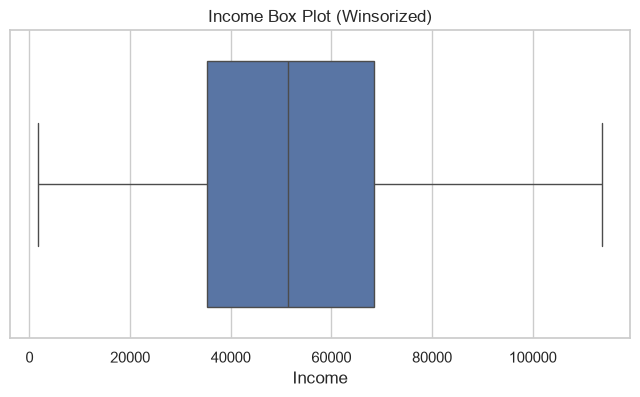

In [9]:

df_before_win = df.copy()  # copy of the dataset before winsorization for future comparison

# combining Alone, Single, YOLO into one SINGLE category


odd_category = df['Marital_Status'].isin(['Alone', 'YOLO'])  
df.loc[odd_category, 'Marital_Status'] = 'Single' 
df.loc[df['Marital_Status'] == 'Absurd', 'Marital_Status'] = 'Other' # Rename Absurd to Other, as it is a more appropriate category name
df['Marital_Status'].value_counts() 


# using Winsorization to limit the effect of high OUTLIER values

mask = df['Income'].notna() 
df.loc[mask, 'Income'] = winsorize(df.loc[mask, 'Income'], limits=[0, 0.004])
print(df['Income'].isna().sum())

df_after_win = df.copy()  # copy of the dataset after winsorization for future comparison

# Visual plot of the winsorized income data

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Income'])
plt.title('Income Box Plot (Winsorized)')
plt.show()


In [10]:

# Check Marital Status-wise Income Analysis after Winsorization

Mean_comparison_mar_win = df.groupby('Marital_Status')['Income'].agg(['size', 'count', 'mean']).reset_index()   
Mean_comparison_mar_win.columns = ['Marital_Status', 'Value_Count', 'Income_Count', 'Mean_Income']
Mean_comparison_mar_win['Missing_Count'] = Mean_comparison_mar_win['Value_Count'] - Mean_comparison_mar_win['Income_Count']   
print("\n Marital Status-wise Income Analysis:\n", Mean_comparison_mar_win)

print("\nTop 12 Highest Income Customers after Winsorization:\n")
print(df.nlargest(12, 'Income')[['ID', 'Education', 'Marital_Status', 'Income']])


# mean Income for each Education + Marital_Status group

print("\n Missing Income List:\n")
Missing_list=df[df["Income"].isnull()][["ID", "Education", "Marital_Status", "Income"]]  # display the missing Income values
print(Missing_list.to_string(index=False))  

group_mean = df.groupby(['Education', 'Marital_Status'])['Income'].transform('mean') 
Missing_list['Income_imputed'] = Missing_list['Income'].fillna(group_mean) # create a new column to indicate missing Income values
print("\n Imputed  Income List:\n")
print(Missing_list.to_string(index=False))  
df['Income'] = df['Income'].fillna(group_mean)  


print("\n Number of missing Income values after filling:", df['Income'].isnull().sum())  
if df['Income'].isnull().sum() == 0:
    print("\n All missing Income values have been filled successfully with the mean of their respective Education + Marital_Status group.")
else:
    print("\n Some missing Income values could not be filled. Please check the data.") 




 Marital Status-wise Income Analysis:
   Marital_Status  Value_Count  Income_Count  Mean_Income  Missing_Count
0       Divorced          232           232     52661.00              0
1        Married          864           857     51568.89              7
2          Other            2             2     72365.50              0
3         Single          485           476     50939.16              9
4       Together          580           573     52043.08              7
5          Widow           77            76     56481.55              1

Top 12 Highest Income Customers after Winsorization:

         ID   Education Marital_Status    Income
210    4619         PhD         Single 113734.00
325    4931  Graduation       Together 113734.00
497    1501         PhD        Married 113734.00
527    9432  Graduation       Together 113734.00
731    1503         PhD       Together 113734.00
853    5336      Master       Together 113734.00
1826   5555  Graduation       Divorced 113734.00
1925  111

STEP3: Creating new feature ==>  New Variable for Children Count, customer age , total spending count and to derive total number of purchases

In [11]:
# Calculate number of children at home and create new column

df['Children_count'] = df['Kidhome'] + df['Teenhome'] # from dataset, Kidhome & Teenhome columns indicate no of children / teen at home
df[['ID','Kidhome', 'Teenhome', 'Children_count']].head(4) 



,ID,Kidhome,Teenhome,Children_count
0,1826,0,0,0
1,1,0,0,0
2,10476,0,1,1
3,1386,1,1,2


In [12]:
# Calculate Age of the customer and create new column

print("Customer enrollment dates Range:", "\n Min:" , df['Dt_Customer'].min(), "\n Max:" , df['Dt_Customer'].max()) 
ref_year = df['Dt_Customer'].dt.year.max()  
df['Age'] = ref_year - df['Year_Birth']  
df[['ID','Year_Birth', 'Dt_Customer', 'Age']].head(4)  



Customer enrollment dates Range: 
 Min: 2012-07-30 00:00:00 
 Max: 2014-06-29 00:00:00


,ID,Year_Birth,Dt_Customer,Age
0,1826,1970,2014-06-16,44
1,1,1961,2014-06-15,53
2,10476,1958,2014-05-13,56
3,1386,1967,2014-05-11,47


In [13]:
# Calculate Total Spending across all product categories and create new column

spend_products = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']  
df['TotalSpending'] = df[spend_products].sum(axis=1) 
df[['ID', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'TotalSpending']].head(4)   



,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalSpending
0,1826,189,104,379,111,189,218,1190
1,1,464,5,64,7,0,37,577
2,10476,134,11,59,15,2,30,251
3,1386,10,0,1,0,0,0,11


In [14]:
# Total purchases over the three channels
purchase_categories = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']   
df['TotalPurchases'] = df[purchase_categories].sum(axis=1)
df[['ID', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases','TotalPurchases']].head(4)



,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,TotalPurchases
0,1826,4,4,6,14
1,1,7,3,7,17
2,10476,3,2,5,10
3,1386,1,0,2,3


In [15]:
print("\n Preview dataset with new feature columns - Children count / Age / Total Spending / Total Purchases \n ")
df[['ID','Children_count', 'Age', 'TotalSpending', 'TotalPurchases']].head(12)  


 Preview dataset with new feature columns - Children count / Age / Total Spending / Total Purchases 
 


,ID,Children_count,Age,TotalSpending,TotalPurchases
0,1826,0,44,1190,14
1,1,0,53,577,17
2,10476,1,56,251,10
3,1386,2,47,11,3
4,5371,1,25,91,6
5,7348,0,56,1192,16
6,4073,0,60,1215,27
7,1991,1,47,96,6
8,4047,1,60,544,17
9,9477,1,60,544,17


STEP4: Gain insights into the distributions and identify outliers

In [16]:
# Review Column list and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   str           
 3   Marital_Status       2240 non-null   str           
 4   Income               2240 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[us]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-null   int64  

Based upon the dataset available, to gain insight considering Integer format columns 'Age', 'Income', 'Children_count', 'Recency', 'TotalSpending', 'TotalPurchases' and check for outliers

4.1 Check AGE category

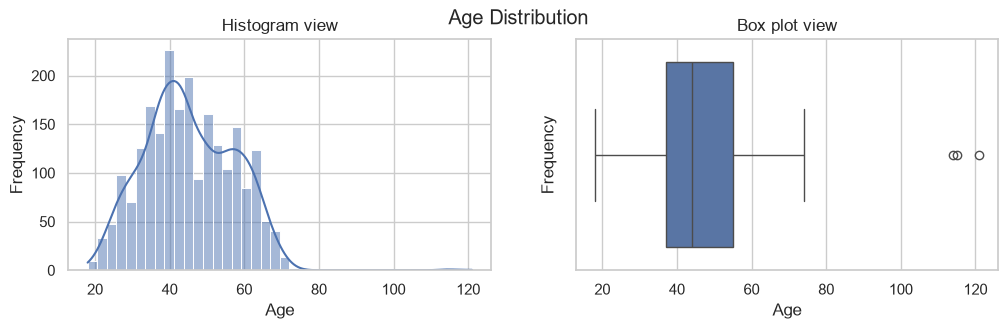


 Age Distribution Summary Statistics:
 count   2240.00
mean      45.19
std       11.98
min       18.00
25%       37.00
50%       44.00
75%       55.00
max      121.00
Name: Age, dtype: float64


In [17]:
# histogram plot and box plot for Age distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['Age'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['Age'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Frequency')

fig.suptitle('Age Distribution')
plt.show()

describe_age = df['Age'].describe()
print("\n Age Distribution Summary Statistics:\n", describe_age)

In [18]:
# Applying IQR method to Identify Outliers in Age column

Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR = Q3_age - Q1_age
lower_age = Q1_age - 1.5 * IQR
upper_age = Q3_age + 1.5 * IQR
outliers_age = df[(df['Age'] < lower_age) | (df['Age'] > upper_age)]
print("\n IQR Method for Identifying Outliers in Age column:")
print("\n Lower bound: ", lower_age)
print(" Upper bound: ", upper_age)
print(" Number of outliers: ", len(outliers_age))
print("\n Age outliers found by IQR:\n")
print(outliers_age[['ID', 'Year_Birth', 'Age', 'Income', 'TotalPurchases']].to_string(index=False))




 IQR Method for Identifying Outliers in Age column:

 Lower bound:  10.0
 Upper bound:  82.0
 Number of outliers:  3

 Age outliers found by IQR:

   ID  Year_Birth  Age   Income  TotalPurchases
11004        1893  121 60182.00               3
 1150        1899  115 83532.00              14
 7829        1900  114 36640.00               5


In [19]:
# The Outliers Age maybe due to data entry errors, so we will remove them from the dataset.
# Filter the dataset to include rows where the Age is within the lower and upper bounds.

print ("\n Removing Rows based on Age column outlier \n")
df = df[(df['Age'] >= lower_age) & (df['Age'] <= upper_age)].copy() # Based upon age value as filter, the rows are removed and saved in dataframe


# 3. check after filtering
if df['ID'].isin(outliers_age['ID']).sum() == 0:     # 0 means those IDs are gone
    print("\n The IDs of the outliers have been removed.")
else:
    print("\n Some IDs of the outliers are still present in the dataset. Please check the filtering logic.")

print("\nFiltered Age range: ", "\n Min Age : ", df['Age'].min(), " \n Max age : ", df['Age'].max())   


 Removing Rows based on Age column outlier 


 The IDs of the outliers have been removed.

Filtered Age range:  
 Min Age :  18  
 Max age :  74


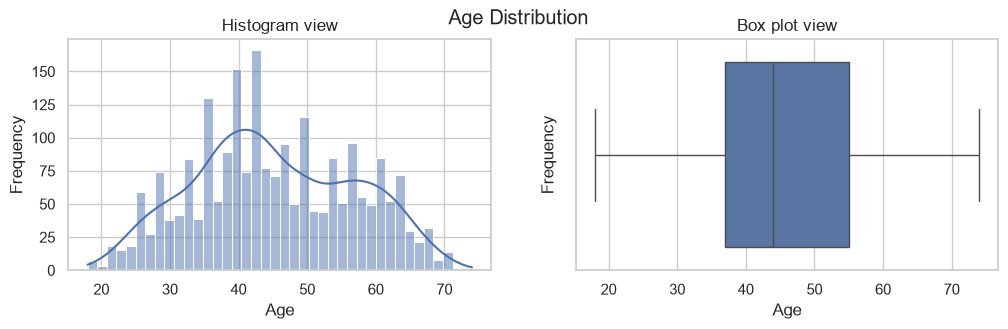


 Age Distribution Summary Statistics:
 count   2237.00
mean      45.10
std       11.70
min       18.00
25%       37.00
50%       44.00
75%       55.00
max       74.00
Name: Age, dtype: float64


In [20]:
# histogram plot and box plot for Age distribution after outlier removal

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['Age'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['Age'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Frequency')

fig.suptitle('Age Distribution')
plt.show()

describe_age = df['Age'].describe()
print("\n Age Distribution Summary Statistics:\n", describe_age)

4.2 Check INCOME category

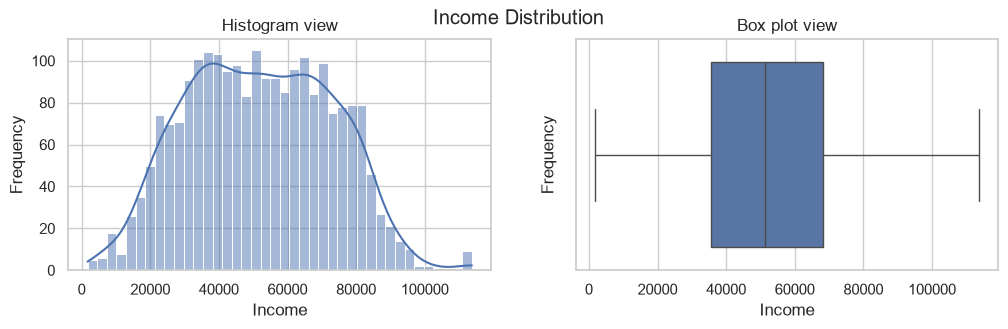


 Income Distribution Summary Statistics:
 count     2237.00
mean     51849.47
std      20898.36
min       1730.00
25%      35523.00
50%      51373.00
75%      68281.00
max     113734.00
Name: Income, dtype: float64


In [21]:
# histogram plot and box plot for Income distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['Income'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['Income'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('Income')
axes[1].set_ylabel('Frequency')

fig.suptitle('Income Distribution')
plt.show()

describe_income = df['Income'].describe()
print("\n Income Distribution Summary Statistics:\n", describe_income)

From the Histogram / Box plot view,  point to recall is that Income data is already winsorized, so the outliers are already capped 

Outlier treatment for Income was completed in Step 2. The top 0.4% of real high incomes were capped with winsorize. 

The plots above confirm no extreme values remain.

Applying IQR method to calculate the bound values on the pre-winsorized dataset , to cross check if the values are within range


In [22]:
# Applying IQR method to Identify Outliers in Income column

# please note that dataset considered in the block is the dataset before winsorization, as we want to see the outliers in the original dataset.

Q1_income = df_before_win['Income'].quantile(0.25)
Q3_income = df_before_win['Income'].quantile(0.75)
IQR = Q3_income - Q1_income
lower_income = Q1_income - 1.5 * IQR
upper_income = Q3_income + 1.5 * IQR
outliers_income = df_before_win[(df_before_win['Income'] < lower_income) | (df_before_win['Income'] > upper_income)]
print("\n IQR Method for Identifying Outliers in Income column:")
print("\n Lower bound: ", lower_income)
print(" Upper bound: ", upper_income)
print(" Number of outliers from original dataset before winsorization: ", len(outliers_income))
print("\n Income outliers found by IQR:\n")
print(outliers_income[['ID', 'Year_Birth', 'Income']].to_string(index=False))

print("\n Current Income Values for Outliers modified with Winsorization:")
print(df[df['ID'].isin(outliers_income['ID'])][['ID', 'Year_Birth', 'Income']])

income_compare = pd.DataFrame({
    'Before Winsorize, incl null value': df_before_win['Income'].describe(),
    'After Winsorize / data imputation': df['Income'].describe()
})
print("\n Income Summary Statistics: Before vs After Winsorization:\n")
print(income_compare.round(2).to_string())


 IQR Method for Identifying Outliers in Income column:

 Lower bound:  -14525.5
 Upper bound:  118350.5
 Number of outliers from original dataset before winsorization:  8

 Income outliers found by IQR:

   ID  Year_Birth    Income
 4931        1977 157146.00
 1501        1982 160803.00
 9432        1977 666666.00
 1503        1976 162397.00
 5336        1971 157733.00
 5555        1975 153924.00
11181        1949 156924.00
 8475        1973 157243.00

 Current Income Values for Outliers modified with Winsorization:
         ID  Year_Birth    Income
325    4931        1977 113734.00
497    1501        1982 113734.00
527    9432        1977 113734.00
731    1503        1976 113734.00
853    5336        1971 113734.00
1826   5555        1975 113734.00
1925  11181        1949 113734.00
2204   8475        1973 113734.00

 Income Summary Statistics: Before vs After Winsorization:

       Before Winsorize, incl null value  After Winsorize / data imputation
count                            2

From the IQR calculation of dataset prior to winsorization, and comparison with current dataset values for Income values, it is Clear that the required values are already with the IQR bound range, so no further outlier treatment is needed

4.3 Check CHILDREN COUNT category

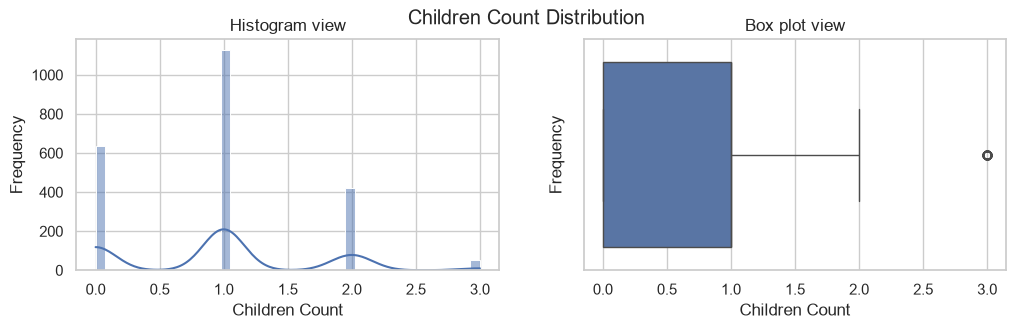


 Children Count Distribution Summary Statistics:
 count   2237.00
mean       0.95
std        0.75
min        0.00
25%        0.00
50%        1.00
75%        1.00
max        3.00
Name: Children_count, dtype: float64


In [23]:
# histogram plot and box plot for Children Count distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['Children_count'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('Children Count')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['Children_count'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('Children Count')
axes[1].set_ylabel('Frequency')

fig.suptitle('Children Count Distribution')
plt.show()

describe_children = df['Children_count'].describe()
print("\n Children Count Distribution Summary Statistics:\n", describe_children)

In [24]:
# Applying IQR method to Identify Outliers in Children Count column

Q1_children = df['Children_count'].quantile(0.25)
Q3_children = df['Children_count'].quantile(0.75)
IQR = Q3_children - Q1_children
lower_children = int(np.ceil(Q1_children - 1.5 * IQR))
upper_children = int(np.floor(Q3_children + 1.5 * IQR))
outliers_children = df[(df['Children_count'] < lower_children) | (df['Children_count'] > upper_children)]
print("\n IQR Method for Identifying Outliers in Children_Count column:")
print("\n Lower bound: ", lower_children )
print(" Upper bound: ", upper_children )
print(" Number of outliers: ", len(outliers_children))
Children_counts_stats = (outliers_children.groupby('Children_count').size().reset_index(name='No of Outliers').rename(columns={'Children_count': 'Total Children Count'}))
if len(outliers_children) > 0:
    print("\n Outliers grouped by Children_count to check if any action needed:\n")
    print(Children_counts_stats.to_string(index=False))



 IQR Method for Identifying Outliers in Children_Count column:

 Lower bound:  -1
 Upper bound:  2
 Number of outliers:  53

 Outliers grouped by Children_count to check if any action needed:

 Total Children Count  No of Outliers
                    3              53


From the IQR test results, the Lower bound / upper bound result is in float, but for Number of Children count per customer, data should be integer, so it is converted to Integer. 

Now the number of outlier is counted as 53
1. It is first identified and grouped how many outlier have similar children count
2. In this result, all 53 outliers have children_count as "3"

Even though the upper bound is capped at 2, Three children count per customer is a valid data point and hence no further action is needed

4.4 Check RECENCY category

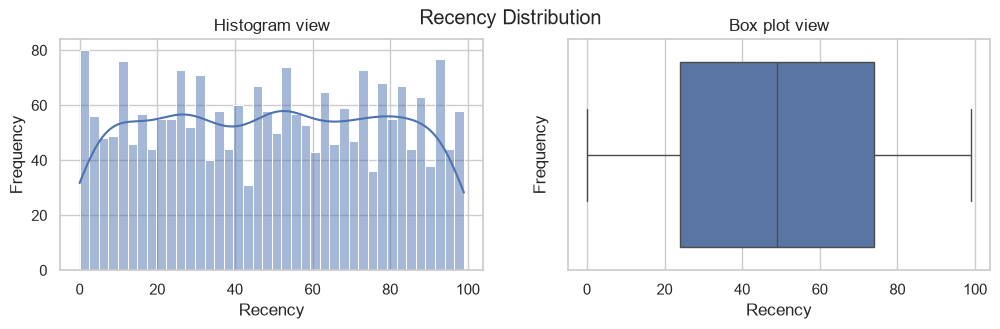


 Recency Distribution Summary Statistics:
 count   2237.00
mean      49.10
std       28.96
min        0.00
25%       24.00
50%       49.00
75%       74.00
max       99.00
Name: Recency, dtype: float64


In [25]:
# histogram plot and box plot for Recency distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['Recency'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('Recency')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['Recency'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('Recency')
axes[1].set_ylabel('Frequency')

fig.suptitle('Recency Distribution')
plt.show()

describe_recency = df['Recency'].describe()
print("\n Recency Distribution Summary Statistics:\n", describe_recency)

In [26]:
# Applying IQR method to Identify Outliers in Recency column

Q1_recency = df['Recency'].quantile(0.25)
Q3_recency = df['Recency'].quantile(0.75)
IQR = Q3_recency - Q1_recency
lower_recency = Q1_recency - 1.5 * IQR
upper_recency = Q3_recency + 1.5 * IQR
outliers_recency = df[(df['Recency'] < lower_recency) | (df['Recency'] > upper_recency)]
print("\n IQR Method for Identifying Outliers in Recency column:")
print("\n Lower bound: ", lower_recency)
print(" Upper bound: ", upper_recency)
print(" Number of outliers: ", len(outliers_recency))
if len(outliers_recency) == 0:
    print("\n No outliers found in Recency column based on IQR method.")
else:
    print("\n Recency outliers found by IQR:\n")
    print(outliers_recency[['ID', 'Year_Birth', 'Recency', 'Income', 'TotalPurchases']].to_string(index=False))





 IQR Method for Identifying Outliers in Recency column:

 Lower bound:  -51.0
 Upper bound:  149.0
 Number of outliers:  0

 No outliers found in Recency column based on IQR method.


4.5 check Total Spending Category

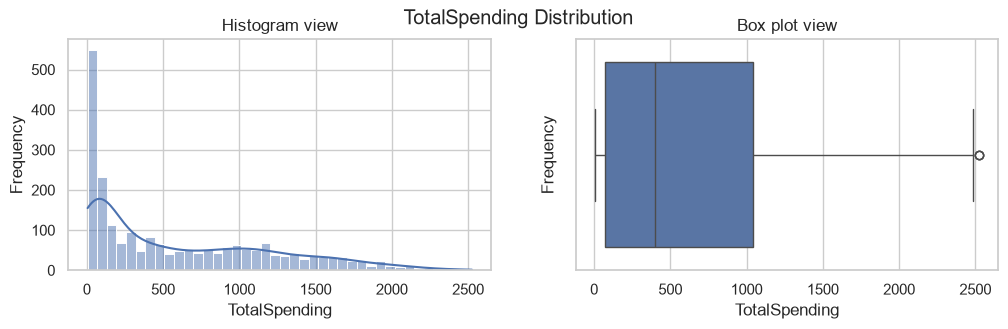


 TotalSpending Distribution Summary Statistics:
 count   2237.00
mean     605.74
std      601.84
min        5.00
25%       69.00
50%      396.00
75%     1045.00
max     2525.00
Name: TotalSpending, dtype: float64


In [27]:
# histogram plot and box plot for TotalSpending distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['TotalSpending'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('TotalSpending')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['TotalSpending'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('TotalSpending')
axes[1].set_ylabel('Frequency')

fig.suptitle('TotalSpending Distribution')
plt.show()

describe_total_spending = df['TotalSpending'].describe()
print("\n TotalSpending Distribution Summary Statistics:\n", describe_total_spending)

In [28]:
# Applying IQR method to Identify Outliers in TotalSpending column

Q1_total_spending = df['TotalSpending'].quantile(0.25)
Q3_total_spending = df['TotalSpending'].quantile(0.75)
IQR = Q3_total_spending - Q1_total_spending
lower_total_spending = Q1_total_spending - 1.5 * IQR
upper_total_spending = Q3_total_spending + 1.5 * IQR
outliers_total_spending = df[(df['TotalSpending'] < lower_total_spending) | (df['TotalSpending'] > upper_total_spending)]
print("\n IQR Method for Identifying Outliers in TotalSpending column:")
print("\n Lower bound: ", lower_total_spending)
print(" Upper bound: ", upper_total_spending)
print(" Number of outliers: ", len(outliers_total_spending))
if len(outliers_total_spending) == 0:
    print("\n No outliers found in TotalSpending column based on IQR method.")
else:
    print("\n TotalSpending outliers found by IQR:\n")
    print(outliers_total_spending[['ID', 'Year_Birth', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds','TotalSpending', 'Income', 'TotalPurchases']].to_string(index=False))




 IQR Method for Identifying Outliers in TotalSpending column:

 Lower bound:  -1395.0
 Upper bound:  2509.0
 Number of outliers:  3

 TotalSpending outliers found by IQR:

  ID  Year_Birth  MntWines  MntFruits  MntMeatProducts  MntFishProducts  MntSweetProducts  MntGoldProds  TotalSpending   Income  TotalPurchases
5735        1991      1156        120              915               94               144            96           2525 90638.00              17
5350        1991      1156        120              915               94               144            96           2525 90638.00              17
1763        1988      1259        172              815               97               148            33           2524 87679.00              28


From the IQR data, there are Three outliers slightly above the upper bound. But looking at amount spent on Individual products, there is no critical reason to remove this data. Outliers don't need to be processed further.

4.6 check Total Purchase category

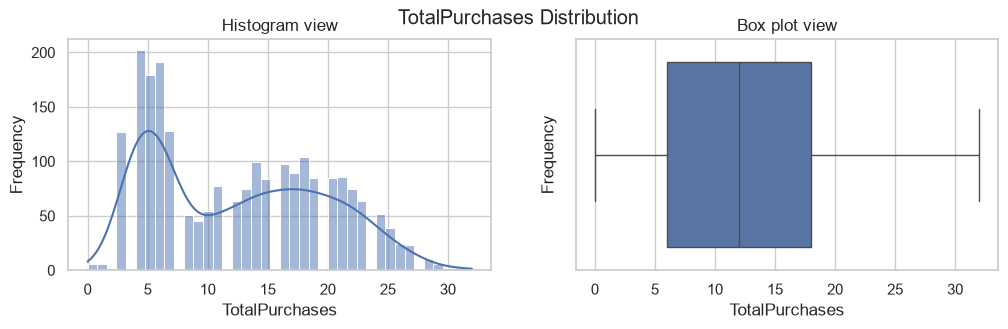


 TotalPurchases Distribution Summary Statistics:
 count   2237.00
mean      12.54
std        7.21
min        0.00
25%        6.00
50%       12.00
75%       18.00
max       32.00
Name: TotalPurchases, dtype: float64


In [29]:
# histogram plot and box plot for TotalPurchases distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 3)) 

sns.histplot(df['TotalPurchases'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Histogram view')
axes[0].set_xlabel('TotalPurchases')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['TotalPurchases'], ax=axes[1])
axes[1].set_title('Box plot view')
axes[1].set_xlabel('TotalPurchases')
axes[1].set_ylabel('Frequency')

fig.suptitle('TotalPurchases Distribution')
plt.show()

describe_total_purchases = df['TotalPurchases'].describe()
print("\n TotalPurchases Distribution Summary Statistics:\n", describe_total_purchases)

In [30]:
# Applying IQR method to Identify Outliers in TotalPurchases column

Q1_total_purchases = df['TotalPurchases'].quantile(0.25)
Q3_total_purchases = df['TotalPurchases'].quantile(0.75)
IQR = Q3_total_purchases - Q1_total_purchases
lower_total_purchases = Q1_total_purchases - 1.5 * IQR
upper_total_purchases = Q3_total_purchases + 1.5 * IQR
outliers_total_purchases = df[(df['TotalPurchases'] < lower_total_purchases) | (df['TotalPurchases'] > upper_total_purchases)]
print("\n IQR Method for Identifying Outliers in TotalPurchases column:")
print("\n Lower bound: ", lower_total_purchases)
print(" Upper bound: ", upper_total_purchases)
print(" Number of outliers: ", len(outliers_total_purchases))
if len(outliers_total_purchases) == 0:
    print("\n No outliers found in TotalPurchases column based on IQR method.")
else:
    print("\n TotalPurchases outliers found by IQR:\n")
    print(outliers_total_purchases[['ID', 'Year_Birth','NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases' ,'TotalSpending', 'Income', 'TotalPurchases']].to_string(index=False))




 IQR Method for Identifying Outliers in TotalPurchases column:

 Lower bound:  -12.0
 Upper bound:  36.0
 Number of outliers:  0

 No outliers found in TotalPurchases column based on IQR method.


No outliers found in TotalPurchases category, so no action needed

Step5 : Encode Categorical Variables

In [31]:
# Need to figure out which columns are of string type and have categorical values

Categorical_columns = df.dtypes[df.dtypes == 'str'].index.tolist()

print("\n Categorical Columns in the dataset:\n", Categorical_columns)

# in these categorical columns, check for unique values

for c in Categorical_columns:
    unique_values = df[c].unique()
    print(" \n unique values for column", c, ":", unique_values)
    
    



 Categorical Columns in the dataset:
 ['Education', 'Marital_Status', 'Country']
 
 unique values for column Education : <StringArray>
['Graduation', 'PhD', '2n Cycle', 'Master', 'Basic']
Length: 5, dtype: str
 
 unique values for column Marital_Status : <StringArray>
['Divorced', 'Single', 'Married', 'Together', 'Widow', 'Other']
Length: 6, dtype: str
 
 unique values for column Country : <StringArray>
['SP', 'CA', 'US', 'AUS', 'GER', 'IND', 'SA', 'ME']
Length: 8, dtype: str


In [32]:
# Education Category have sequence order, so assigning order number based on sequence - Ordinary Encoding

education_order = {'Basic': 1, '2n Cycle': 2, 'Graduation': 3, 'Master': 4, 'PhD': 5} 
df['Education_Encoded'] = df['Education'].map(education_order)
print("\n Education column after ordinary encoding: \n\n", df[['Education', 'Education_Encoded']].head(10))
print("\n Unmapped Education values:", df['Education_Encoded'].isnull().sum())


 Education column after ordinary encoding: 

     Education  Education_Encoded
0  Graduation                  3
1  Graduation                  3
2  Graduation                  3
3  Graduation                  3
4  Graduation                  3
5         PhD                  5
6    2n Cycle                  2
7  Graduation                  3
8         PhD                  5
9         PhD                  5

 Unmapped Education values: 0


In [33]:
# Marital Status category have no sequence order, so using One Hot Encoding to create new columns for each category

Marital_Encoded = pd.get_dummies(df['Marital_Status'], prefix='Marital_Status', dtype=int) 
print("\n Marital Status columns after One Hot Encoding: \n\n", Marital_Encoded.head(10))



 Marital Status columns after One Hot Encoding: 

    Marital_Status_Divorced  Marital_Status_Married  Marital_Status_Other  \
0                        1                       0                     0   
1                        0                       0                     0   
2                        0                       1                     0   
3                        0                       0                     0   
4                        0                       0                     0   
5                        0                       0                     0   
6                        0                       1                     0   
7                        0                       0                     0   
8                        0                       1                     0   
9                        0                       1                     0   

   Marital_Status_Single  Marital_Status_Together  Marital_Status_Widow  
0                      0             

In [34]:
# Country Status category have no sequence order, so using One Hot Encoding to create new columns for each category

Country_Encoded = pd.get_dummies(df['Country'], prefix='Country', dtype=int)
print("\n Country columns after One Hot Encoding: \n\n", Country_Encoded.head(10))



 Country columns after One Hot Encoding: 

    Country_AUS  Country_CA  Country_GER  Country_IND  Country_ME  Country_SA  \
0            0           0            0            0           0           0   
1            0           1            0            0           0           0   
2            0           0            0            0           0           0   
3            1           0            0            0           0           0   
4            0           0            0            0           0           0   
5            0           0            0            0           0           0   
6            0           0            1            0           0           0   
7            0           0            0            0           0           0   
8            0           0            0            0           0           0   
9            0           0            0            1           0           0   

   Country_SP  Country_US  
0           1           0  
1           0     

In [35]:
## df_encoded is the copy with the Encoded columns added
df_encoded = pd.concat([df, Marital_Encoded, Country_Encoded], axis=1)  
print(df_encoded.shape)  
df_encoded.columns.tolist()

(2237, 47)


['ID',
 'Year_Birth',
 'Education',
 'Marital_Status',
 'Income',
 'Kidhome',
 'Teenhome',
 'Dt_Customer',
 'Recency',
 'MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Response',
 'Complain',
 'Country',
 'Children_count',
 'Age',
 'TotalSpending',
 'TotalPurchases',
 'Education_Encoded',
 'Marital_Status_Divorced',
 'Marital_Status_Married',
 'Marital_Status_Other',
 'Marital_Status_Single',
 'Marital_Status_Together',
 'Marital_Status_Widow',
 'Country_AUS',
 'Country_CA',
 'Country_GER',
 'Country_IND',
 'Country_ME',
 'Country_SA',
 'Country_SP',
 'Country_US']

Step 6: Generate HEATMAP for correlation between Variables 

In [36]:
# find the Variable columns with number values

Correlation_Column_selection  = df_encoded[['Income', 'Recency','NumDealsPurchases' , 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases','NumWebVisitsMonth', 'Response', 'Complain', 'Age', 'TotalSpending','TotalPurchases', 'Education_Encoded']]
#Correlation_Column_selection  = df_encoded[['Income', 'Recency','NumDealsPurchases' ,'MntFruits', 'MntMeatProducts', 'MntFishProducts','MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases','NumWebVisitsMonth', 'Response', 'Complain', 'Age', 'TotalSpending','TotalPurchases', 'Education_Encoded']]
Correlation_Column_selection.info()
print(Correlation_Column_selection.columns)


<class 'pandas.DataFrame'>
Index: 2237 entries, 0 to 2239
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Income               2237 non-null   float64
 1   Recency              2237 non-null   int64  
 2   NumDealsPurchases    2237 non-null   int64  
 3   NumWebPurchases      2237 non-null   int64  
 4   NumCatalogPurchases  2237 non-null   int64  
 5   NumStorePurchases    2237 non-null   int64  
 6   NumWebVisitsMonth    2237 non-null   int64  
 7   Response             2237 non-null   int64  
 8   Complain             2237 non-null   int64  
 9   Age                  2237 non-null   int64  
 10  TotalSpending        2237 non-null   int64  
 11  TotalPurchases       2237 non-null   int64  
 12  Education_Encoded    2237 non-null   int64  
dtypes: float64(1), int64(12)
memory usage: 244.7 KB
Index(['Income', 'Recency', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStor

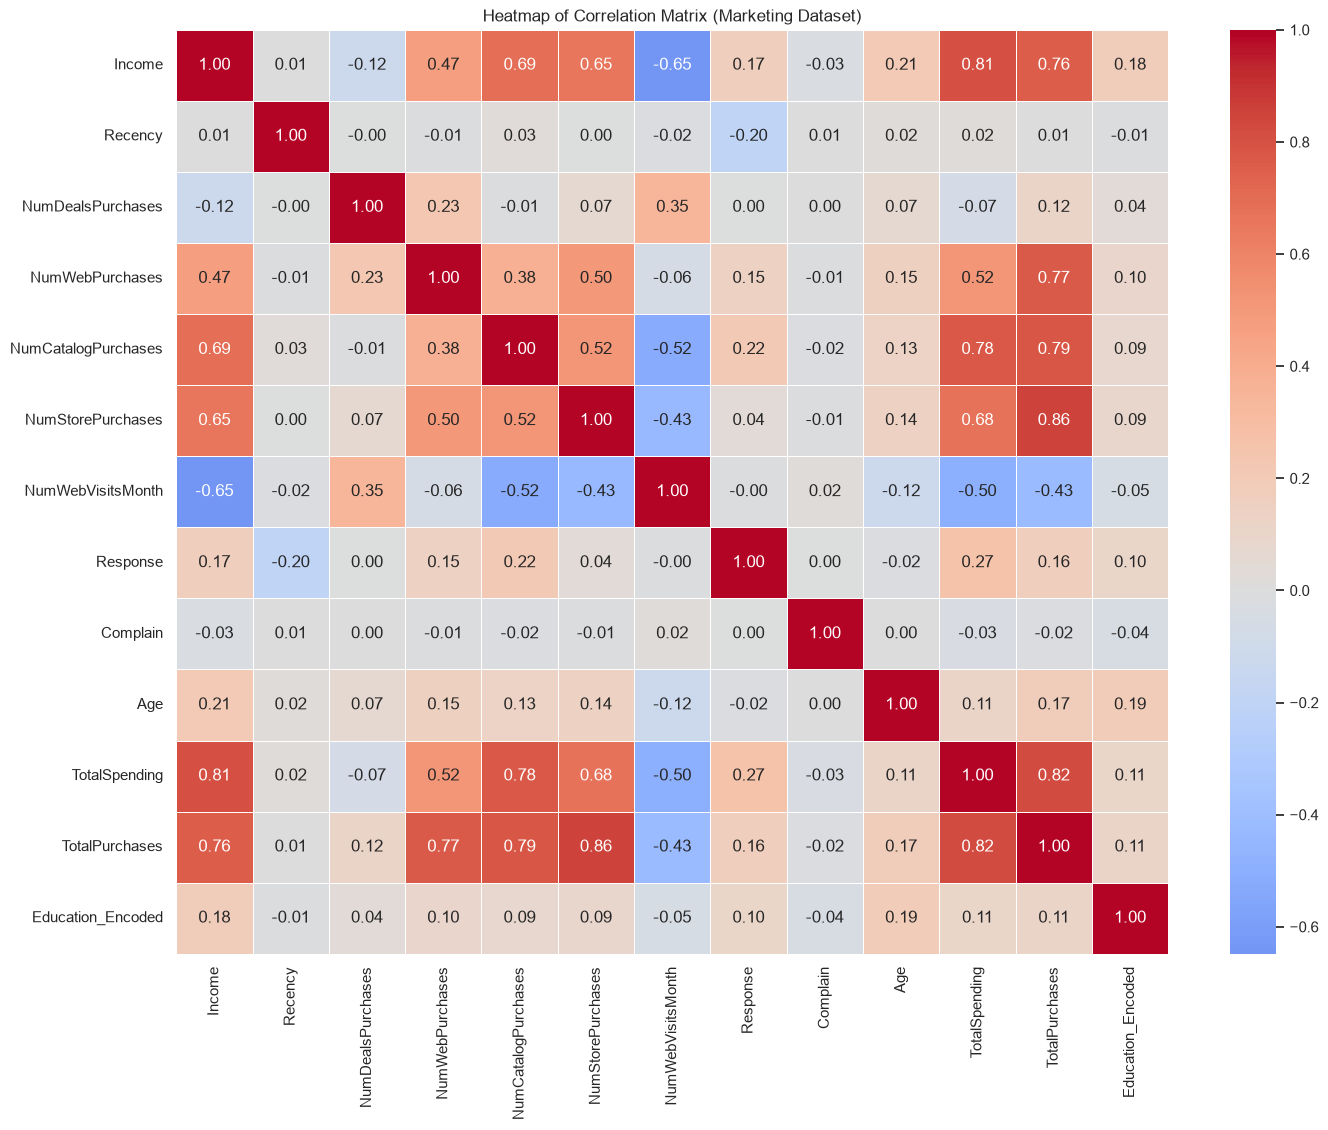

In [37]:

# Calculate correlation matrix 

Correlation = Correlation_Column_selection.corr()

# Plot heatmap
plt.figure(figsize=(16,12))
sns.heatmap(Correlation, annot=True, cmap='coolwarm', fmt=".2f", center=0, linewidths=0.5)
plt.title('Heatmap of Correlation Matrix (Marketing Dataset)')
plt.show()

In [38]:
# use this to check data values for individual item from correlation data format
# print(Correlation['TotalPurchases'].drop('TotalPurchases').sort_values(ascending=False).round(2).to_string())

Heatmap correlation ( Note - Correlation shows link not cause )

1. Income is linked to TotalSpending(0.81) and TotalPurchases (0.76), Higher the Income, enables high spending / total purchases
2. Income is linked to significant Store Purchase (0.65), Catalog Purchase and Web Purchases (0.47)
3. Significant Number of Deals Purchases( purchases made with discount) is linked with the number of visits to company's website (0.35), purchases are made through company's website (0.23)
4. Days since last purchase, Recency does not have strong correlation with Spending / total purchase pattern
5. Customer Complaint is minimal (0.02) but is linked with the number of visits to company's website
6. Customer Recent purchase data is linked as negative correlation (-0.2) with response to company offer
7. Age has Weak link with Website visits / online purchase
8. Even with higher Income, the Web Purchases (0.47) is still less than Store Purchases (0.65) / Catalog Purchases (0.69). Customers still prefer to shop in store comparatively.

Step 7: Test the Hypotheses
===========================

7.1 Hypothesis #1 

Older individuals may not possess the same level of technological proficiency and may, therefore, lean toward traditional in-store shopping preferences

Independent Variable - Older Customers do not possess the same level of technological proficiency as young customers (Age Criteria)

Dependent Variable   - Older customers lean towards in-store shopping preferences (InStore purchase)

7.1.1 Hypothesis Statement 

Null Hypothesis - H0 - Older customers do not make more in-store shopping than younger customers. 

Alternate Hypothesis - Ha - Older customers make more in-store shopping than younger customers

7.1.2 Level of Significance 

Consider level of significance- 5% , set Alpha= 0.05  (probability of occurrence of Type-1 error)

7.1.3 Test Type 

Selected test type is Z-Test     (based upon high sample size )

In [39]:
H1_med_age = df['Age'].median()                                         # calculate Median of Age
H1_older_cust = df.loc[df['Age'] >= H1_med_age, 'NumStorePurchases']    # calculate NumStorePurchases, based on Older age customer criteria with median
H1_younger_cust = df.loc[df['Age'] < H1_med_age, 'NumStorePurchases']   # calculate NumStorePurchases, based on Young age customer criteria with median

print("\n Median age :", H1_med_age)  
print("\n Based on Median value \n older_count :", len(H1_older_cust), "\n younger_count :", len(H1_younger_cust))  
print("\n Mean value of purchases \n older_mean :", round(H1_older_cust.mean(), 2), "\n younger_mean :", round(H1_younger_cust.mean(), 2))  


 Median age : 44.0

 Based on Median value 
 older_count : 1150 
 younger_count : 1087

 Mean value of purchases 
 older_mean : 6.23 
 younger_mean : 5.33


In [40]:
# Z- Test

ztest_score, p_value= ztest(H1_older_cust, H1_younger_cust, alternative='larger')
print("\n ZTest Results", " \n ztest_score", round(ztest_score,3), "\n p_value", p_value)
alpha = 0.05
if(p_value < alpha):                            # if p-value is smaller than alpha, reject the null hypothesis, else fail to reject it
    print(" \n Reject null Hypothesis")
else:
    print(" \n Fail to Reject null Hypothesis")


 ZTest Results  
 ztest_score 6.627 
 p_value 1.7104491825317213e-11
 
 Reject null Hypothesis


From the Hypothesis Testing, it is observed
- P-Value is smaller than the Alpha 0.05 so the Null Hypothesis is rejected
- from the mean value of purchases, it is observed that Older Customer Mean Purchase is Larger than Younger Customer Mean Purchase but the difference is minimal

CONCLUSION

Older Customers do make more purchases than Young customers, but there is no additional proof that it is because of technology

7.2 Hypothesis #2

Customers with children likely experience time constraints, making online shopping a more convenient option

Independent Variable - Customer with Children likely experience time constraints (Children count criteria)

Dependent Variable   - Online shopping is convenient (Online Web purchase)

7.2.1 Hypotheses Statement 

Null Hypotheses - H0 - Customer with children do not prefer online shopping over customer without children

Alternate Hypotheses - Ha - Customer with children prefer online shopping

7.2.2 Level of Significance 

Consider level of significance- 5% , set Alpha= 0.05  (probability of occurrence of Type-1 error)

7.2.3 Test Type 

Selected test type is Z-Test     (based upon high sample size )

In [41]:

H2_cust_with_kids = df[df['Children_count'] > 0]
H2_cust_no_kids = df[df['Children_count'] == 0 ]
print("\n Customer Data : ", 
      "\n Total Number of Customers with kids : ", len(H2_cust_with_kids), 
      "\n Total number of customers without kids : ", len(H2_cust_no_kids))                               
print("\n Mean Values : ", 
      "\n Mean value of Customers with kids : ", round(H2_cust_with_kids['NumWebPurchases'].mean(),2),
      "\n Mean value of Customers without kids : ", round(H2_cust_no_kids['NumWebPurchases'].mean(),2))

 


 Customer Data :  
 Total Number of Customers with kids :  1600 
 Total number of customers without kids :  637

 Mean Values :  
 Mean value of Customers with kids :  3.96 
 Mean value of Customers without kids :  4.39


In [42]:
# Z- Test

H2_ztest_score, H2_p_value= ztest(H2_cust_with_kids['NumWebPurchases'], H2_cust_no_kids['NumWebPurchases'], alternative='larger')
print("\n ZTest Results", " \n H2_ztest_score", round(H2_ztest_score,3), "\n H2_p_value", H2_p_value)
alpha = 0.05
if(H2_p_value < alpha):                            # if p-value is smaller than alpha, reject the null hypothesis, else fail to reject it
    print(" \n Reject null Hypothesis")
else:
    print(" \n Fail to Reject null Hypothesis")


 ZTest Results  
 H2_ztest_score -3.302 
 H2_p_value 0.9995201526327769
 
 Fail to Reject null Hypothesis


From the Hypothesis Testing, it is observed
- P-Value is Larger than the Alpha 0.05 so failed to Reject Null Hypothesis
- from the mean value of purchases, it is observed that Mean Web Purchase (3.96) of Customer with children is less than the Mean Web Purchase(4.39) of customer without children

CONCLUSION

Customers with children do not prefer online shopping/ web purchases, when compared with customers without children

7.3 Hypothesis #3

Sales at physical stores may face the risk of cannibalization by alternative distribution channels

Note: There are three variables define Sales distribution channels - In-Store / Catalog / Website 

Independent Variable - Alternative distribution channels (Catalog / Online Web purchase)

Dependent Variable   - Sales at physical stores (In-Store sale criteria)

7.3.1 Hypotheses Statement 

Null Hypotheses - H0 - Sales at physical stores is not affected by alternate distribution channels

Alternate Hypotheses - Ha - Sales at physical stores is affected by alternate distribution channels

7.3.2 Level of Significance 

Consider level of significance- 5% , set Alpha= 0.05  (probability of occurrence of Type-1 error)

7.3.3 Test Type 

Selected test type is Z-Test     (based upon high sample size )

In [43]:

H3_Alternate_Distribution_channels = df['NumWebPurchases'] + df['NumCatalogPurchases']
H3_Alternate_Distribution_Channels_Median = H3_Alternate_Distribution_channels.median() 
# Median calculated for Alternate Distribution channels, the idea is to check how many in-store purchases made between higher group vs lower group of the median
H3_Alternate_Distribution_Channels_High = df.loc[H3_Alternate_Distribution_channels >= H3_Alternate_Distribution_Channels_Median, 'NumStorePurchases'] 
H3_Alternate_Distribution_Channels_Low = df.loc[H3_Alternate_Distribution_channels < H3_Alternate_Distribution_Channels_Median, 'NumStorePurchases']
print("\n Median of Alternate Distribution Channels : ", H3_Alternate_Distribution_Channels_Median)   
print("\n Customers in High group : ", len(H3_Alternate_Distribution_Channels_High),
      "\n Customers in Low group : ", len(H3_Alternate_Distribution_Channels_Low))                   
print("\n Mean store purchases - High : ", round(H3_Alternate_Distribution_Channels_High.mean(), 2),
      "\n Mean store purchases - Low : ", round(H3_Alternate_Distribution_Channels_Low.mean(), 2))
   


 Median of Alternate Distribution Channels :  6.0

 Customers in High group :  1209 
 Customers in Low group :  1028

 Mean store purchases - High :  7.84 
 Mean store purchases - Low :  3.39


In [44]:
# Z- Test

H3_ztest_score, H3_p_value = ztest(H3_Alternate_Distribution_Channels_High, H3_Alternate_Distribution_Channels_Low, alternative='two-sided')   
print("\n ZTest Results", " \n H3_ztest_score", round(H3_ztest_score, 3), "\n H3_p_value", H3_p_value)
alpha = 0.05                                       
if(H3_p_value < alpha):                            # if p-value is smaller than alpha, reject the null hypothesis, else fail to reject it
    print(" \n Reject null Hypothesis")
else:
    print(" \n Fail to Reject null Hypothesis")


 ZTest Results  
 H3_ztest_score 44.066 
 H3_p_value 0.0
 
 Reject null Hypothesis


From the Hypothesis Testing, it is observed
- P-Value is Less than the Alpha 0.05 approx 0.0 , so Null Hypothesis is Rejected
- from the mean value of store purchases, it is observed that customers in the high web/catalog group average 7.84 store purchases against 3.39 in the low group. The Customer who use high Alternate Distribution channel for purchases , still do high in-store purchases. 

CONCLUSION

Physical stores sales are affected by alternate distribution channel Catalog/Web sales
Customers who purchase more in Web / Catalog channel, linked with and contribute to more amount of purchases at in-store as well. so Sales is high and is in positive sign, no sign of cannibalization

7.4 Hypothesis #4

Does the United States significantly outperform the rest of the world in total purchase volumes?


Independent Variable - Customer Country (Country)

Dependent Variable   - Total Purchases (NumTotalPurchases)

7.4.1 Hypotheses Statement 

Null Hypotheses - H0 - US do not have higher Total Purchase Volumes than rest of the world

Alternate Hypotheses - Ha - US do have higher Total Purchase Volumes;

7.4.2 Level of Significance 

Consider level of significance- 5% , set Alpha= 0.05  (probability of occurrence of Type-1 error)

7.4.3 Test Type 

Selected test type is Z-Test     (based upon high sample size )

In [45]:
H4_US_Customers = df.loc[df['Country'] == 'US', 'TotalPurchases']      
H4_Rest_Of_World_Customers = df.loc[df['Country'] != 'US', 'TotalPurchases']   
# Dependent variable is TotalPurchases, independent variable is the country group (US vs rest of the world)

print("\n Customers in US group : ", len(H4_US_Customers),
      "\n Customers in Rest of World group : ", len(H4_Rest_Of_World_Customers))              
print("\n Mean total purchases - US : ", round(H4_US_Customers.mean(), 2),
      "\n Mean total purchases - Rest of World : ", round(H4_Rest_Of_World_Customers.mean(), 2))   


 Customers in US group :  109 
 Customers in Rest of World group :  2128

 Mean total purchases - US :  13.51 
 Mean total purchases - Rest of World :  12.49


In [46]:
# Z- Test

H4_ztest_score, H4_p_value = ztest(H4_US_Customers, H4_Rest_Of_World_Customers, alternative='larger')   
print("\n ZTest Results", "\n H4_ztest_score", round(H4_ztest_score, 3), "\n H4_p_value", H4_p_value)
alpha = 0.05                                       
if(H4_p_value < alpha):                            # # if p-value is smaller than alpha, reject the null hypothesis, else fail to reject it
    print(" \n Reject null Hypothesis")
else:
    print(" \n Fail to Reject null Hypothesis")


 ZTest Results 
 H4_ztest_score 1.441 
 H4_p_value 0.07481013353156878
 
 Fail to Reject null Hypothesis


From the Hypothesis Testing, it is observed
 - P-Value is approx 0.075, which is greater than the alpha 0.05, so the Null Hypothesis is Not Rejected (Fail to Reject)
 - From the mean value of total purchases, it is observed that US customers average 13.51 total purchases against 12.49 for the rest of the world. The US average is slightly higher, but the difference is not statistically significant. 
  - The US customer group is also small compared to Rest of the World Customers(109 customers against 2,128), which makes test less reliable

CONCLUSION

There is not enough evidence to say that US customers purchase more than the rest of the world.
The US average is a little higher, but the gap could be due to chance, so there is no significant sign that the US buys more.

STEP 8: VISUALIZATION

8.1	Identify the top-performing products and those with the lowest revenue

From the dataset, six columns identify the amount spent on specific products, previously identified while calculating the total spending 
- Wines
- Fruits
- Meat Products
- Fish Products
- Sweet Products
- Gold Products

MntWines            680038
MntMeatProducts     373393
MntGoldProds         98358
MntFishProducts      83939
MntSweetProducts     60553
MntFruits            58767
dtype: int64


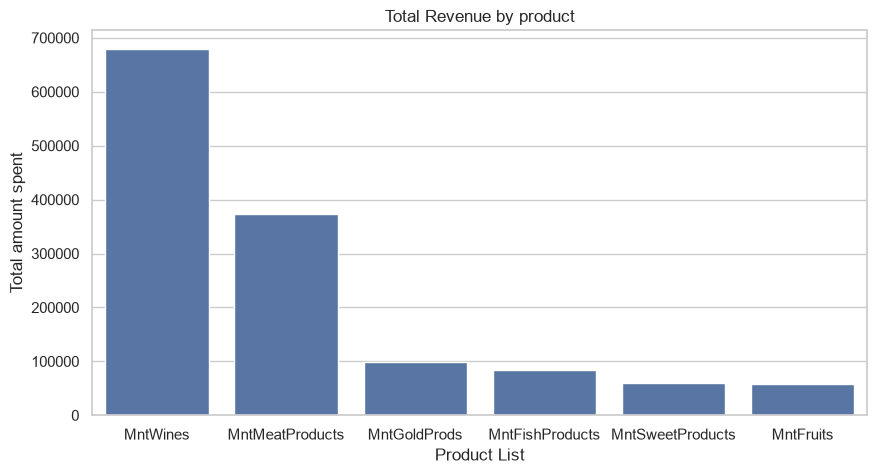

In [47]:
Product_Review = df[spend_products].sum().sort_values(ascending=False)
print(Product_Review)

plt.figure(figsize=(10, 5))
sns.barplot(x=Product_Review.index, y=Product_Review.values)
plt.xlabel('Product List')
plt.ylabel('Total amount spent')
plt.title('Total Revenue by product')
plt.show()

Conclusion

From the Visualization of per product amount spent data,  it is identified the following
- Top Performing Products - Wines and Meat Products
- Low Performing Products - Fruits and Sweet Products

8.2 Examine if there is a correlation between customers' age and the acceptance rate of the last campaign

          count  mean
AgeGroup             
18-30       259  0.18
31-40       588  0.14
41-50       649  0.15
51-60       475  0.14
61-70       257  0.16
71-80         9  0.33


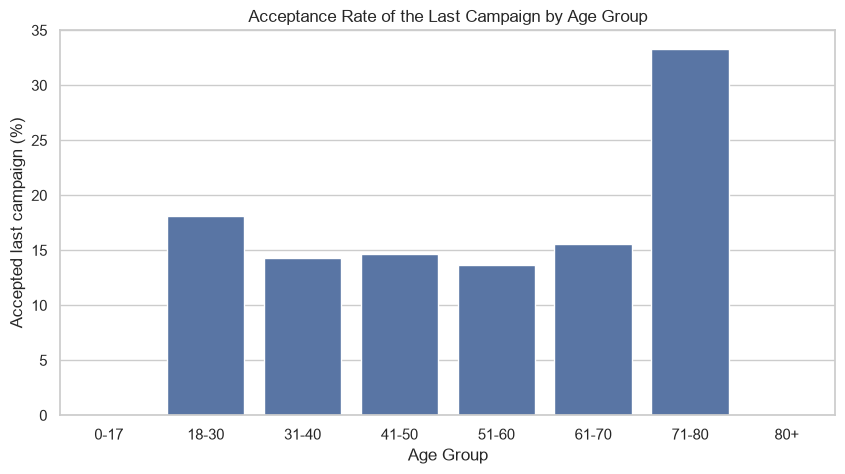

In [48]:
# using Data Binning method to categorize age group and calculation mean of the Response received for last campaign

vis_8_2_bins_edges = [0, 17, 30, 40, 50, 60, 70, 80, np.inf]
vis_8_2_bins_labels = ['0-17', '18-30', '31-40', '41-50', '51-60', '61-70', '71-80', '80+']
df['AgeGroup'] = pd.cut(df['Age'], bins=vis_8_2_bins_edges, labels=vis_8_2_bins_labels)   
Age_Resp = df.groupby('AgeGroup')['Response'].agg(['count', 'mean'])                       
print(Age_Resp)

# Bar plot
plt.figure(figsize=(10, 5))                                                                
sns.barplot(x=Age_Resp.index, y=Age_Resp['mean'] * 100)                                    
plt.xlabel('Age Group')                                                                   
plt.ylabel('Accepted last campaign (%)')                                                   
plt.title('Acceptance Rate of the Last Campaign by Age Group')                             
plt.show()             

Conclusion

From the Visualization of Last campaign acceptance rate per age group,  it is identified the following
- Acceptance rate is Higher for Age Group 71-80 but total number of customer group is very less compared to other Age Group
- Higher customer count is identified in  Age group, '31-40', '41-50', '51-60' but the Acceptance rate is similar and does not provide strong link

In summary, Age alone is not sufficient to conclude Acceptance rate of last campaign

8.3	Determine the country with the highest number of customers who accepted the last campaign

         Accepted  Customers  Acceptance_Rate
Country                                      
SP            176       1094            16.09
SA             52        336            15.48
CA             38        268            14.18
AUS            23        160            14.37
GER            17        120            14.17
IND            13        147             8.84
US             13        109            11.93
ME              2          3            66.67


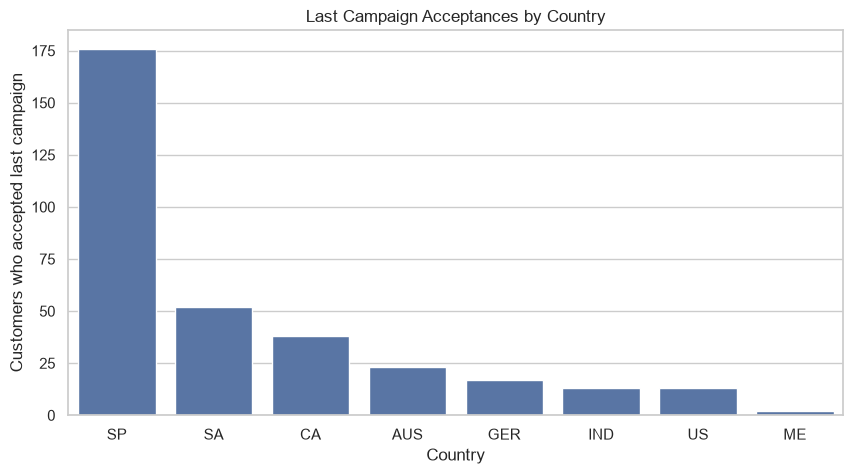

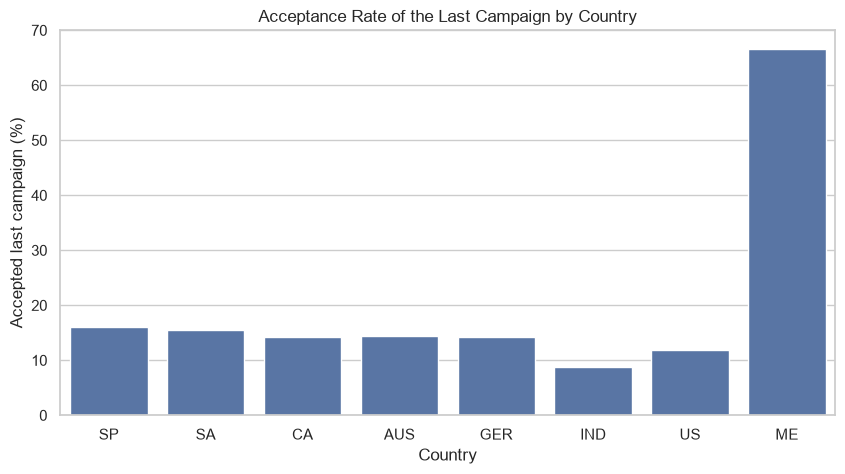

In [49]:
# using groupby to calculate the number of customers who accepted the last campaign, and the acceptance rate, for each country

Country_Resp = df.groupby('Country')['Response'].agg(['sum', 'count', 'mean'])    
Country_Resp.columns = ['Accepted', 'Customers', 'Acceptance_Rate']               
Country_Resp['Acceptance_Rate'] = Country_Resp['Acceptance_Rate'] * 100           
Country_Resp = Country_Resp.sort_values('Accepted', ascending=False)              
print(Country_Resp)

# Bar plot (number of customers who accepted)
plt.figure(figsize=(10, 5))                                                       
sns.barplot(x=Country_Resp.index, y=Country_Resp['Accepted'])                     
plt.xlabel('Country')                                                             
plt.ylabel('Customers who accepted last campaign')                                
plt.title('Last Campaign Acceptances by Country')                                 
plt.show()                                                                        

# Bar plot (acceptance rate, fair comparison between large and small countries)
plt.figure(figsize=(10, 5))                                                       
sns.barplot(x=Country_Resp.index, y=Country_Resp['Acceptance_Rate'])              
plt.xlabel('Country')                                                             
plt.ylabel('Accepted last campaign (%)')                                          
plt.title('Acceptance Rate of the Last Campaign by Country')                      
plt.show()                                                                        

Conclusion

From the Visualization of Last campaign acceptance by country, it is identified the following
- Spain (SP) has the highest total number of accepted customers (176), but if we look at total number of customer per country it is not fair comparison
- Acceptance rate should give more fair comparison and ME shows a 66.7% Acceptance rate but has only 3 customers, so it is not needed and stick with original result of Spain has highest acceptance.

In summary, from the visualization, it is identified the country with most acceptance of last campaign is SPAIN (SP). additional point to note is that Spain has the more number of customers.

8.4 Investigate if there is a discernible pattern in the number of children at home and the total expenditure

                count    mean  median
Children_count                       
0                 637 1104.86 1189.00
1                1126  473.50  306.00
2                 421  245.95   93.00
3                  53  274.60   88.00


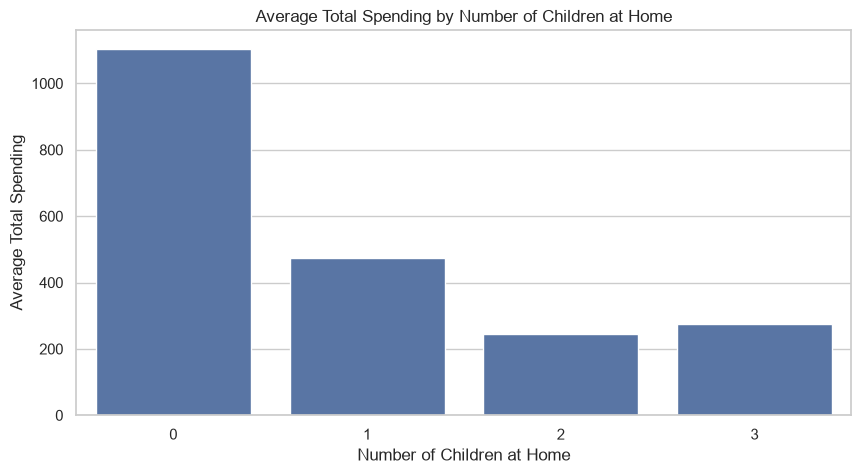

In [50]:
# using groupby to calculate the number of customers, the mean and the median of Total Spending for each Children count

Children_Spend = df.groupby('Children_count')['TotalSpending'].agg(['count', 'mean', 'median'])   
print(Children_Spend)

# Bar plot (mean spending)
plt.figure(figsize=(10, 5))                                                       
sns.barplot(x=Children_Spend.index, y=Children_Spend['mean'])                    
plt.xlabel('Number of Children at Home')                                          
plt.ylabel('Average Total Spending')                                              
plt.title('Average Total Spending by Number of Children at Home')                 
plt.show()                                                                        

Conclusion

From the Visualization of Total Spending by number of children at home, it is identified the following

- The median spending is about 1,189 with no children and it decreases with more children. so Spending reduces as the number of children increases. 
- The group with 3 children is small, so its numbers are less reliable

In summary, the number of children at home strongly affects spending. Customers with no children are the biggest spenders, and customers with two or more children spend the least


8.5	Analyze the educational background of customers who lodged complaints in the last two years

            Complaints  Customers  Complaint_Rate
Education                                        
Graduation          14       1127            1.24
2n Cycle             3        201            1.49
Master               2        370            0.54
PhD                  1        485            0.21
Basic                0         54            0.00


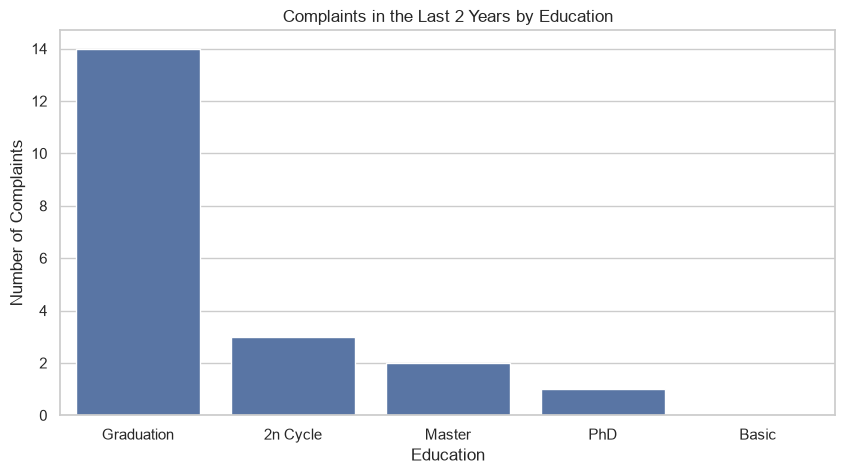

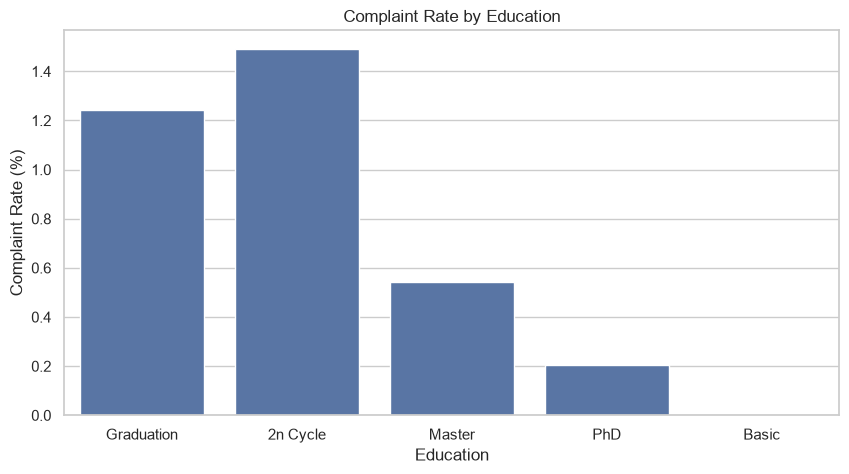

In [51]:
Education_Complain = df.groupby('Education')['Complain'].agg(['sum', 'count', 'mean'])    
Education_Complain.columns = ['Complaints', 'Customers', 'Complaint_Rate']               
Education_Complain['Complaint_Rate'] = Education_Complain['Complaint_Rate'] * 100        
Education_Complain = Education_Complain.sort_values('Complaints', ascending=False)       
print(Education_Complain)

# Bar plot (number of complaints)
plt.figure(figsize=(10, 5))                                                      
sns.barplot(x=Education_Complain.index, y=Education_Complain['Complaints'])       
plt.xlabel('Education')                                                          
plt.ylabel('Number of Complaints')                                                
plt.title('Complaints in the Last 2 Years by Education')                          
plt.show()                                       
                                 
# Bar plot (complaint rate view as the customer count differs)
plt.figure(figsize=(10, 5))                                                       
sns.barplot(x=Education_Complain.index, y=Education_Complain['Complaint_Rate'])   
plt.xlabel('Education')                                                           
plt.ylabel('Complaint Rate (%)')                                                  
plt.title('Complaint Rate by Education')                                           
plt.show()                   

Conclusion

From the Visualization of complaints by Education, it is identified the following
- Most complaints come from Graduation customers (14), followed by 2n Cycle (3), the customer count also differs a lot. 
- If we look at Complain rate % against total number of customers per group, highest is 2n Cycle (1.49) , followed by Graduation (1.24). As the Percentage is less , complaints are rare overall.


In summary,  Graduation has the most complaints due to its biggest group.


In [52]:
# save the final data to csv
df.to_csv('marketing_data_cleaned_final.csv', index=False)  
print("saved final df")

saved final df


SUMMARY
========

The goal of this project was to use exploratory data analysis and hypothesis testing to understand the factors that influence customer acquisition and purchasing behavior.

Exploratory Data Analysis
---------------------------

- Operations performed of the raw data -  Fix Data Types, Data Imputation, Treat Outliers, Feature Engineering and then the data was ready for analysis.

- Income is the strongest factor: higher income goes with higher total spending (0.81) and more purchases (0.76).

- Children at home lower spending sharply. Customers with no children are the biggest spenders.

- Products: Wine and Meat bring most of the revenue, while Fruits and Sweets bring the least.

- Customers still prefer store and catalog purchases to the web, even at higher incomes.

- Spain is the biggest market

Hypothesis Testing summary (Z-test, α = 0.05)
-----------------------------------------------

- H1, Older customers shop more in store: supported. Older customers make more store purchases, but the difference is small, and there is no proof that technology skill is the cause.

- H2, Customers with children shop more online: not supported. They make fewer web purchases than customers without children.

- H3, Other channels affect store sales: supported, but in a positive direction. Customers who use web and catalog more also buy more in the store, so there is no cannibalization.

- H4, US buys more than the rest of the world: not supported. The difference is not significant, and the US group is small.

Campaign response
------------------

- Age and country alone do not explain who accepted the last campaign. Spain has the most acceptances mainly because it is the biggest market, and the acceptance rates of the large countries are close.

- Complaints are rare, and Education does not explain them.

Business takeaway
------------------

Customer acquisition and purchasing depend mostly on income and family situation, not on age or country. The company should target higher-income customers and customers without children with premium offers, and give families cheaper offers. Wine and Meat should lead promotions. Web, catalog and store should be run as one connected strategy, because they support each other and do not compete.

*Correlation shows a link, not a cause.